# ==============================================================================
# ECG MULTICLASS CLASSIFICATION  -  ONE-CELL GOOGLE COLAB VERSION
# Classes: ARR (Arrhythmia), AFF (Atrial Fibrillation),
#          CHF (Congestive Heart Failure), NSR (Normal Sinus Rhythm)
#
# HOW TO RUN
#   1. Colab -> New notebook -> paste this whole file into ONE cell.
#   2. Run it. When asked, upload  ecg_data_cleaned__human_.csv
#      (or put the file in /content beforehand and it is found automatically).
#
# WHAT WAS FIXED vs. the old notebook
#   * The CSV has NO header row. Old code treated row 1 as column names (lost a
#     sample, produced names like "74.9256689791873"). Now: header=None + names.
#   * Old code looked for a different file (ECGCvdata.csv) with named columns.
#   * Old code forced the MLP as "champion", then called shap.TreeExplainer on it
#     (crashes: MLP is not a tree model). Champion is now chosen by CV score and
#     SHAP automatically uses the right explainer.
#   * Hard-coded text ("9.82% missing", "N=240") replaced with computed values;
#     this CSV has 0 missing values.
#   * Added: duplicate removal, shuffled-label sanity check, Colab upload/download.
# ==============================================================================

In [1]:
# %% STEP 0: INSTALL (only what Colab is missing) -------------------------------
import subprocess, sys, importlib
for _pkg, _mod in [("shap", "shap"), ("lime", "lime"), ("catboost", "catboost"),
                   ("xgboost", "xgboost"), ("lightgbm", "lightgbm")]:
    try:
        importlib.import_module(_mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip


In [2]:
#%% STEP 1: IMPORTS -------------------------------------------------------------
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     learning_curve, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import f_classif
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, balanced_accuracy_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             classification_report, roc_curve, auc)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier)
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import shap
import lime.lime_tabular

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.dpi"] = 110
print("Libraries ready.")

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries ready.


In [3]:
# %% STEP 2: LOAD DATA (headerless CSV) -----------------------------------------
N_FEATURES = 54
# If you have the original column names, paste a list of 54 names here.
# Otherwise generic names feature_1 ... feature_54 are used.
FEATURE_NAMES = None
FEATURE_NAMES = FEATURE_NAMES or [f"feature_{i}" for i in range(1, N_FEATURES + 1)]
assert len(FEATURE_NAMES) == N_FEATURES, "FEATURE_NAMES must contain 54 names"

CSV_NAME = "ecg_data_cleaned__human_.csv"
candidates = [CSV_NAME, f"/content/{CSV_NAME}"] + sorted(glob.glob("/content/*ecg*.csv"))
data_path = next((p for p in candidates if os.path.exists(p)), None)

if data_path is None:                       # not found -> ask for upload (Colab)
    try:
        from google.colab import files
        print("Please upload your ECG csv file ...")
        uploaded = files.upload()
        data_path = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_NAME} next to this script.")

columns = ["RECORD_ID"] + FEATURE_NAMES + ["ECG_signal"]
df_raw = pd.read_csv(data_path, header=None, names=columns)   # <- the key fix

print(f"Loaded: {data_path}")
print(f"Shape : {df_raw.shape[0]} rows x {df_raw.shape[1]} columns "
      f"(1 id + {N_FEATURES} features + 1 label)")
assert df_raw.shape[1] == N_FEATURES + 2, "Unexpected number of columns"
display(df_raw.head(3))

FileNotFoundError: Put ecg_data_cleaned__human_.csv next to this script.

In [ ]:
# %% STEP 3: DATA AUDIT ----------------------------------------------------------
target_col = "ECG_signal"
feature_cols = FEATURE_NAMES

print("=" * 78); print("DATA AUDIT"); print("=" * 78)
print("Class distribution:\n", df_raw[target_col].value_counts().to_string())
print("\nMissing values   :", int(df_raw[feature_cols].isnull().sum().sum()))
print("Infinite values  :", int(np.isinf(df_raw[feature_cols].values).sum()))
n_dups = int(df_raw[feature_cols].duplicated().sum())
print("Duplicate feature rows:", n_dups)
const_cols = [c for c in feature_cols if df_raw[c].nunique() == 1]
print(f"Constant (zero-variance) features: {len(const_cols)} -> harmless, kept for "
      "compatibility with a 54-feature model")

rec = df_raw.groupby(target_col)["RECORD_ID"].agg(["count", "min", "max"])
print("\nRECORD_ID range per class (it is just a row counter, sorted by class):")
display(rec)
print("=> RECORD_ID would let a model 'cheat' (id 1-300 = ARR ...). It is EXCLUDED.")

# remove exact duplicate feature vectors (keeps first)
df = df_raw.drop_duplicates(subset=feature_cols, keep="first").reset_index(drop=True)
print(f"\nAfter removing duplicates: {len(df)} samples")


DATA AUDIT
Class distribution:
 ECG_signal
ARR    300
AFF    300
CHF    300
NSR    300

Missing values   : 0
Infinite values  : 0
Duplicate feature rows: 2
Constant (zero-variance) features: 7 -> harmless, kept for compatibility with a 54-feature model

RECORD_ID range per class (it is just a row counter, sorted by class):


,count,min,max
ECG_signal,,,
AFF,300,301,600
ARR,300,1,300
CHF,300,601,900
NSR,300,901,1200


=> RECORD_ID would let a model 'cheat' (id 1-300 = ARR ...). It is EXCLUDED.

After removing duplicates: 1198 samples


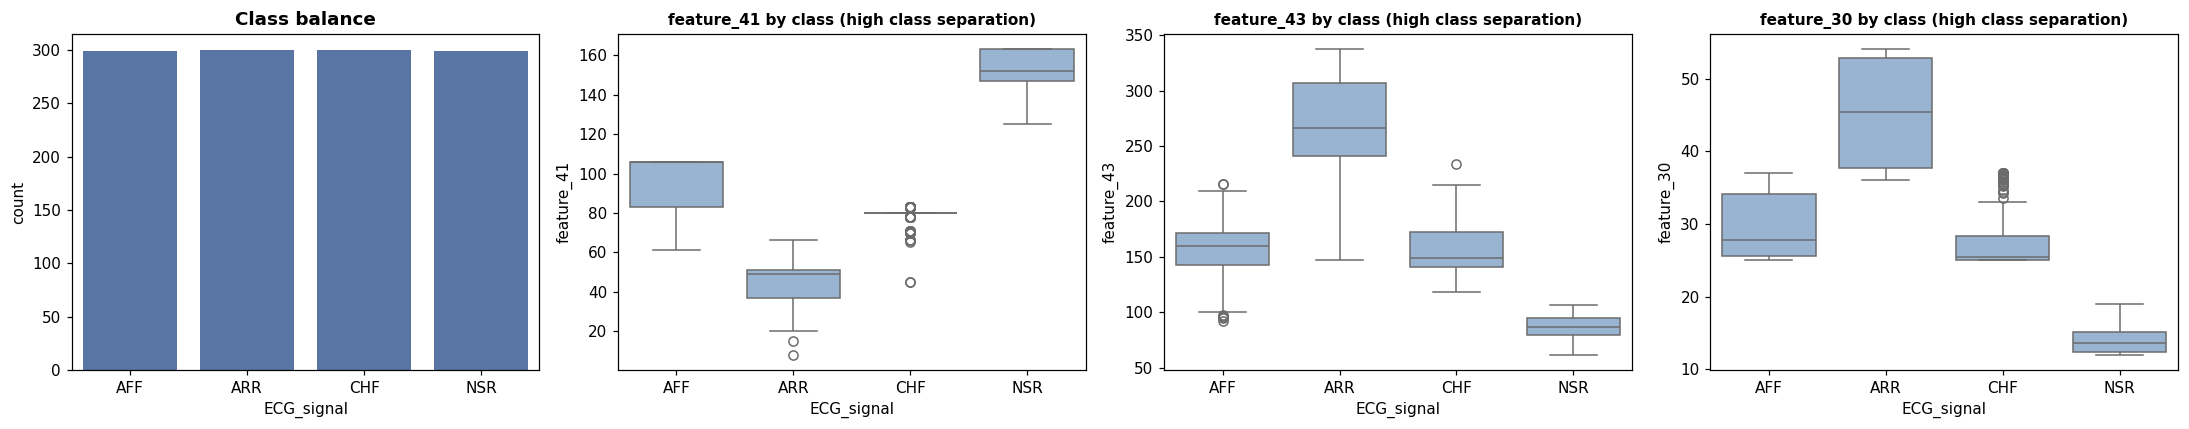

In [ ]:
# %% STEP 4: QUICK VISUAL AUDIT --------------------------------------------------
X_all = df[feature_cols]
F, _ = f_classif(X_all.fillna(X_all.median()), df[target_col])
top3 = [feature_cols[i] for i in np.argsort(np.nan_to_num(F))[::-1][:3]]
order = sorted(df[target_col].unique())

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
sns.countplot(data=df, x=target_col, order=order, ax=axes[0], color="#4C72B0")
axes[0].set_title("Class balance", fontweight="bold")
for ax, col in zip(axes[1:], top3):
    sns.boxplot(data=df, x=target_col, y=col, order=order, ax=ax, color="#8FB4D9")
    ax.set_title(f"{col} by class (high class separation)", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# %% STEP 5: ENCODE + STRATIFIED TRAIN / TEST SPLIT -----------------------------
X = df[feature_cols].values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[target_col].values)
class_names = list(label_encoder.classes_)
n_classes = len(class_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Classes          : {dict(zip(class_names, range(n_classes)))}")
print(f"Development set  : {len(y_train)} samples {dict(zip(class_names, np.bincount(y_train).tolist()))}")
print(f"Hold-out test set: {len(y_test)} samples {dict(zip(class_names, np.bincount(y_test).tolist()))}")
print("The test set is NOT used for model selection - only for the final evaluation.")


Classes          : {'AFF': 0, 'ARR': 1, 'CHF': 2, 'NSR': 3}
Development set  : 958 samples {'AFF': 239, 'ARR': 240, 'CHF': 240, 'NSR': 239}
Hold-out test set: 240 samples {'AFF': 60, 'ARR': 60, 'CHF': 60, 'NSR': 60}
The test set is NOT used for model selection - only for the final evaluation.


In [ ]:
# %% STEP 6: LEAKAGE-FREE PIPELINES + MODEL ZOO ---------------------------------
def build_pipeline(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("classifier", model))
    return Pipeline(steps)

# name: (model, needs_scaling, is_tree_model)
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), True, False),
    "Gaussian Naive Bayes": (GaussianNB(), True, False),
    "KNN": (KNeighborsClassifier(n_neighbors=7, weights="distance"), True, False),
    "SVM (RBF)": (SVC(kernel="rbf", C=10.0, gamma="scale", probability=True, random_state=RANDOM_STATE), True, False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), False, True),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), False, True),
    "Gradient Boosting": (GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE), False, True),
    "XGBoost": (XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
                              colsample_bytree=0.8, eval_metric="mlogloss",
                              random_state=RANDOM_STATE, verbosity=0), False, True),
    "LightGBM": (LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1), False, True),
    "CatBoost": (CatBoostClassifier(iterations=300, depth=6, learning_rate=0.05,
                                    loss_function="MultiClass", random_state=RANDOM_STATE,
                                    verbose=0), False, True),
    "MLP Neural Network": (MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-4,
                                         max_iter=1000, random_state=RANDOM_STATE), True, False),
}
print(f"{len(models)} models registered.")

11 models registered.


Model                  | CV Macro-F1      | CV Accuracy      | CV ROC-AUC      
------------------------------------------------------------------------------
Logistic Regression    | 0.9697 ± 0.0143 | 0.9697 ± 0.0142 | 0.9970 ± 0.0005
Gaussian Naive Bayes   | 0.9172 ± 0.0117 | 0.9165 ± 0.0115 | 0.9883 ± 0.0025
KNN                    | 0.9718 ± 0.0071 | 0.9718 ± 0.0070 | 0.9981 ± 0.0014
SVM (RBF)              | 0.9864 ± 0.0063 | 0.9864 ± 0.0063 | 0.9988 ± 0.0013
Random Forest          | 0.9906 ± 0.0069 | 0.9906 ± 0.0069 | 0.9997 ± 0.0003
Extra Trees            | 0.9958 ± 0.0021 | 0.9958 ± 0.0021 | 0.9999 ± 0.0001
Gradient Boosting      | 0.9843 ± 0.0057 | 0.9843 ± 0.0057 | 0.9994 ± 0.0005
XGBoost                | 0.9854 ± 0.0061 | 0.9854 ± 0.0061 | 0.9997 ± 0.0003
LightGBM               | 0.9895 ± 0.0047 | 0.9896 ± 0.0047 | 0.9997 ± 0.0003
CatBoost               | 0.9875 ± 0.0071 | 0.9875 ± 0.0071 | 0.9995 ± 0.0005
MLP Neural Network     | 0.9895 ± 0.0047 | 0.9896 ± 0.0047 | 0.9995 ± 0

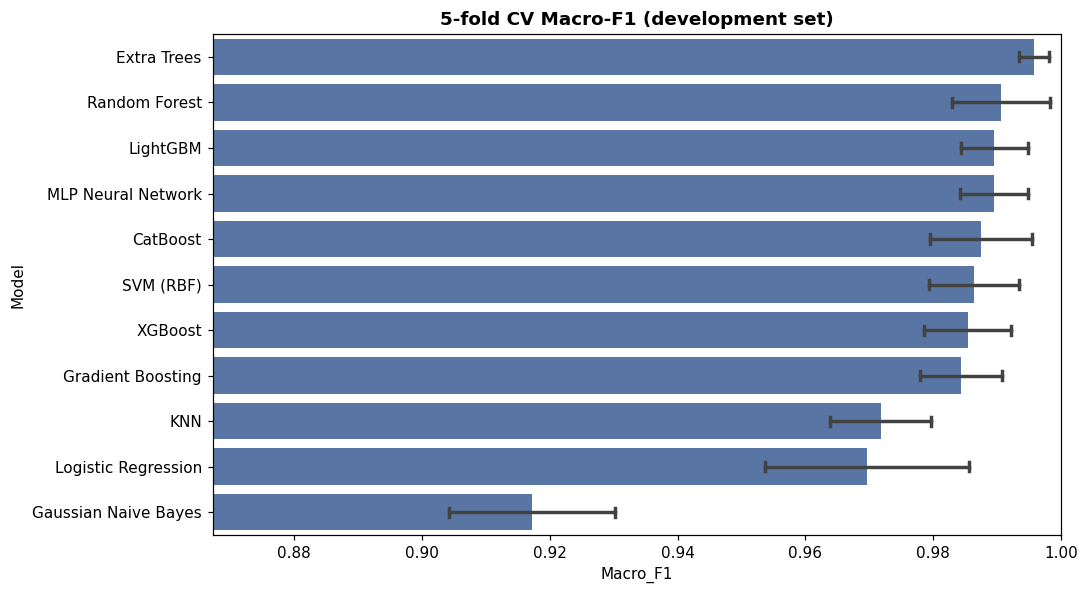

In [ ]:
# %% STEP 7: 5-FOLD CV BENCHMARK (development set only) -------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fold_rows = [], []
print(f"{'Model':<22} | {'CV Macro-F1':<16} | {'CV Accuracy':<16} | {'CV ROC-AUC':<16}")
print("-" * 78)
for name, (mdl, scale, _) in models.items():
    f1s, accs, aucs = [], [], []
    for k, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
        pipe = build_pipeline(mdl, scale).fit(X_train[tr], y_train[tr])
        pred = pipe.predict(X_train[va])
        prob = pipe.predict_proba(X_train[va])
        f1s.append(f1_score(y_train[va], pred, average="macro"))
        accs.append(accuracy_score(y_train[va], pred))
        aucs.append(roc_auc_score(y_train[va], prob, multi_class="ovr", average="macro"))
        fold_rows.append({"Model": name, "Fold": k, "Macro_F1": f1s[-1]})
    rows.append({"Model": name, "F1": np.mean(f1s), "F1_sd": np.std(f1s),
                 "Acc": np.mean(accs), "Acc_sd": np.std(accs),
                 "AUC": np.mean(aucs), "AUC_sd": np.std(aucs)})
    print(f"{name:<22} | {np.mean(f1s):.4f} ± {np.std(f1s):.4f} | "
          f"{np.mean(accs):.4f} ± {np.std(accs):.4f} | {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")

df_cv = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
df_folds = pd.DataFrame(fold_rows)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=df_folds, x="Macro_F1", y="Model", order=df_cv["Model"],
            color="#4C72B0", errorbar="sd", capsize=0.2, ax=ax)
ax.set_xlim(max(0.0, df_cv["F1"].min() - 0.05), 1.0)
ax.set_title("5-fold CV Macro-F1 (development set)", fontweight="bold")
plt.tight_layout(); plt.show()

In [ ]:
# %% STEP 8: CHAMPION = BEST CV MODEL -------------------------------------------
CHAMPION_OVERRIDE = None        # e.g. "MLP Neural Network" to force a model
champion_name = CHAMPION_OVERRIDE or df_cv.loc[0, "Model"]
champ_model, champ_scale, champ_is_tree = models[champion_name]
champ_cv_f1 = float(df_cv.loc[df_cv["Model"] == champion_name, "F1"].iloc[0])

print("=" * 78)
print(f"CHAMPION MODEL: {champion_name}   (CV Macro-F1 = {champ_cv_f1:.4f})")
print("Selected on cross-validation only - the test set was never consulted.")
print("=" * 78)
final_pipeline = build_pipeline(champ_model, champ_scale).fit(X_train, y_train)

CHAMPION MODEL: Extra Trees   (CV Macro-F1 = 0.9958)
Selected on cross-validation only - the test set was never consulted.


Train Macro-F1: 1.0000 | CV Macro-F1: 0.9958 | gap: 0.0042


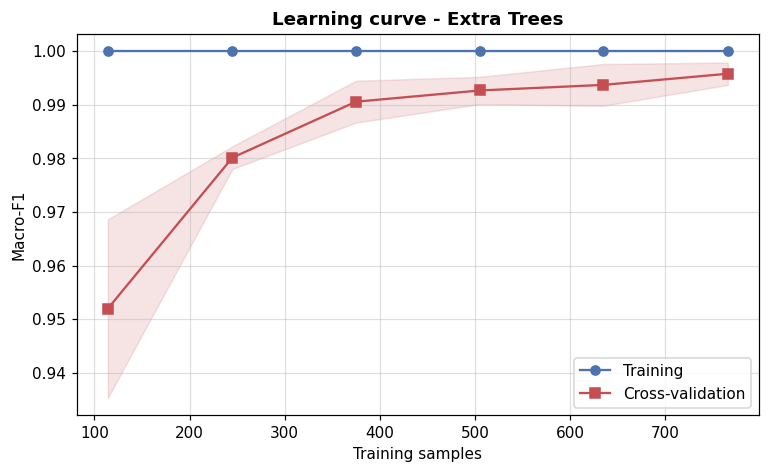

Shuffled-label CV accuracy: 0.244  (chance = 0.250)  -> OK, no label leakage


In [ ]:
# %% STEP 9: OVERFITTING CHECK + LEARNING CURVE + SHUFFLED-LABEL SANITY CHECK ----
train_f1 = f1_score(y_train, final_pipeline.predict(X_train), average="macro")
print(f"Train Macro-F1: {train_f1:.4f} | CV Macro-F1: {champ_cv_f1:.4f} | "
      f"gap: {train_f1 - champ_cv_f1:.4f}")

sizes, tr_sc, va_sc = learning_curve(
    build_pipeline(champ_model, champ_scale), X_train, y_train, cv=cv,
    scoring="f1_macro", train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1,
    random_state=RANDOM_STATE)
plt.figure(figsize=(8, 4.5))
plt.plot(sizes, tr_sc.mean(1), "o-", label="Training", color="#4C72B0")
plt.plot(sizes, va_sc.mean(1), "s-", label="Cross-validation", color="#C44E52")
plt.fill_between(sizes, tr_sc.mean(1) - tr_sc.std(1), tr_sc.mean(1) + tr_sc.std(1), alpha=.15, color="#4C72B0")
plt.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=.15, color="#C44E52")
plt.title(f"Learning curve - {champion_name}", fontweight="bold")
plt.xlabel("Training samples"); plt.ylabel("Macro-F1"); plt.legend(); plt.grid(alpha=.4)
plt.show()

# Sanity check: with SHUFFLED labels accuracy must drop to ~25% (4 classes).
# If it stayed high, the pipeline would be leaking label information.
y_shuf = np.random.default_rng(RANDOM_STATE).permutation(y_train)
shuf_acc = cross_val_score(build_pipeline(champ_model, champ_scale), X_train, y_shuf,
                           cv=cv, scoring="accuracy").mean()
print(f"Shuffled-label CV accuracy: {shuf_acc:.3f}  (chance = {1/n_classes:.3f})  "
      f"-> {'OK, no label leakage' if shuf_acc < 0.35 else 'WARNING: investigate leakage'}")

In [ ]:
# %% STEP 10: FINAL HOLD-OUT TEST EVALUATION ------------------------------------
y_pred = final_pipeline.predict(X_test)
y_prob = final_pipeline.predict_proba(X_test)
y_bin = np.eye(n_classes)[y_test]

test_acc = accuracy_score(y_test, y_pred)
test_prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
test_rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
test_bal = balanced_accuracy_score(y_test, y_pred)
test_roc = roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro")
test_pr = average_precision_score(y_bin, y_prob, average="macro")

print("=" * 78)
print(f"HOLD-OUT TEST RESULTS - {champion_name} (N = {len(y_test)})")
print("=" * 78)
print(f"Accuracy          : {test_acc:.4f}")
print(f"Macro Precision   : {test_prec:.4f}")
print(f"Macro Recall      : {test_rec:.4f}")
print(f"Macro F1          : {test_f1:.4f}")
print(f"Balanced Accuracy : {test_bal:.4f}")
print(f"Macro ROC-AUC     : {test_roc:.4f}")
print(f"Macro PR-AUC      : {test_pr:.4f}")
print(f"CV - Test F1 gap  : {champ_cv_f1 - test_f1:+.4f}\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

HOLD-OUT TEST RESULTS - Extra Trees (N = 240)
Accuracy          : 0.9875
Macro Precision   : 0.9875
Macro Recall      : 0.9875
Macro F1          : 0.9875
Balanced Accuracy : 0.9875
Macro ROC-AUC     : 0.9993
Macro PR-AUC      : 0.9981
CV - Test F1 gap  : +0.0084

              precision    recall  f1-score   support

         AFF     0.9833    0.9833    0.9833        60
         ARR     0.9836    1.0000    0.9917        60
         CHF     0.9831    0.9667    0.9748        60
         NSR     1.0000    1.0000    1.0000        60

    accuracy                         0.9875       240
   macro avg     0.9875    0.9875    0.9875       240
weighted avg     0.9875    0.9875    0.9875       240



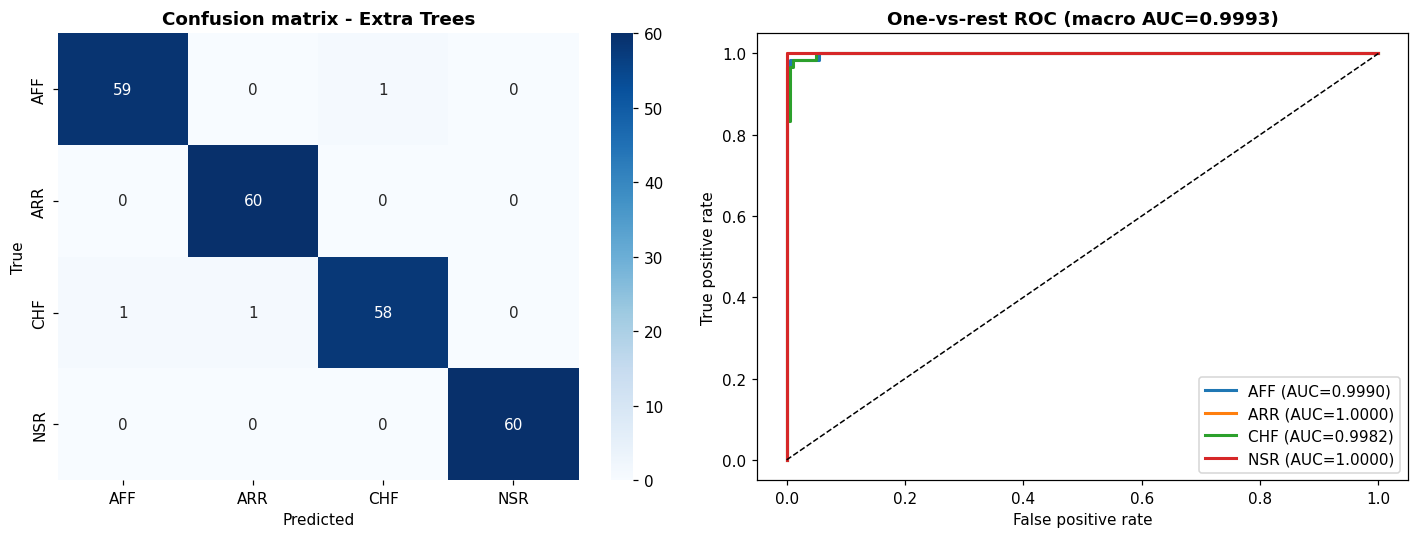

In [ ]:
# %% STEP 11A: CONFUSION MATRIX + ROC --------------------------------------------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=a1)
a1.set_title(f"Confusion matrix - {champion_name}", fontweight="bold")
a1.set_xlabel("Predicted"); a1.set_ylabel("True")
for i, cn in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    a2.plot(fpr, tpr, lw=2, label=f"{cn} (AUC={auc(fpr, tpr):.4f})")
a2.plot([0, 1], [0, 1], "k--", lw=1)
a2.set_title(f"One-vs-rest ROC (macro AUC={test_roc:.4f})", fontweight="bold")
a2.set_xlabel("False positive rate"); a2.set_ylabel("True positive rate"); a2.legend(loc="lower right")
plt.tight_layout(); plt.show()

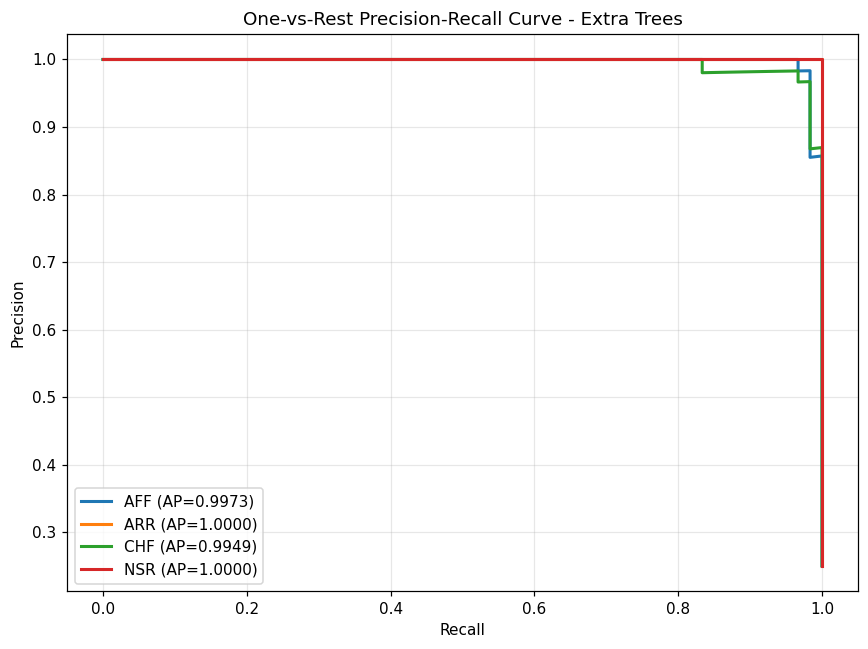

In [ ]:
# %% STEP 11B: PRECISION-RECALL CURVE --------------------------------------------

from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))

for i, cn in enumerate(class_names):
    precision, recall, _ = precision_recall_curve(
        y_bin[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_bin[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall,
        precision,
        lw=2,
        label=f"{cn} (AP={ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    f"One-vs-Rest Precision-Recall Curve - {champion_name}"
)

plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# %% STEP 12: BOOTSTRAP 95% CONFIDENCE INTERVALS --------------------------------
rng = np.random.default_rng(RANDOM_STATE)
b_acc, b_f1, b_roc = [], [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if len(np.unique(y_test[idx])) < n_classes:
        continue
    b_acc.append(accuracy_score(y_test[idx], y_pred[idx]))
    b_f1.append(f1_score(y_test[idx], y_pred[idx], average="macro", zero_division=0))
    b_roc.append(roc_auc_score(y_test[idx], y_prob[idx], multi_class="ovr", average="macro"))
ci = lambda v: (np.percentile(v, 2.5), np.percentile(v, 97.5))
ci_acc, ci_f1, ci_roc = ci(b_acc), ci(b_f1), ci(b_roc)
print(f"Accuracy 95% CI : [{ci_acc[0]:.4f}, {ci_acc[1]:.4f}]")
print(f"Macro-F1 95% CI : [{ci_f1[0]:.4f}, {ci_f1[1]:.4f}]")
print(f"Macro-ROC 95% CI: [{ci_roc[0]:.4f}, {ci_roc[1]:.4f}]")

Accuracy 95% CI : [0.9708, 1.0000]
Macro-F1 95% CI : [0.9716, 1.0000]
Macro-ROC 95% CI: [0.9979, 1.0000]



Computing SHAP values ...


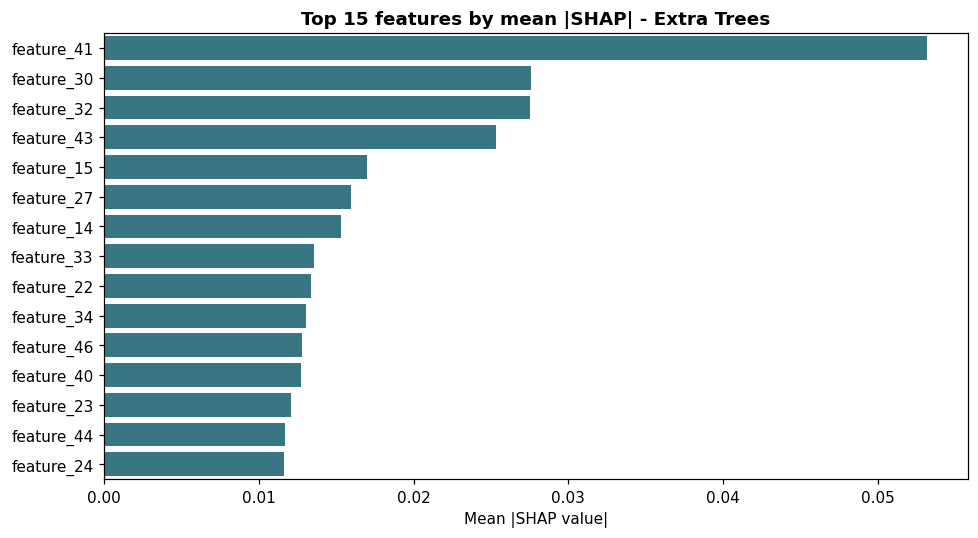

In [ ]:
# %% STEP 13: SHAP (explainer chosen automatically) -----------------------------
print("\nComputing SHAP values ...")
pre = final_pipeline[:-1]                       # imputer (+ scaler)
clf = final_pipeline.named_steps["classifier"]
X_test_t = pre.transform(X_test)
def to_3d(sv):
    """-> array (samples, features, classes) for any SHAP version"""
    return np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)

if champ_is_tree:
    shap_arr = to_3d(shap.TreeExplainer(clf).shap_values(X_test_t))
else:   # non-tree model (MLP, SVM, KNN, ...) -> model-agnostic KernelExplainer
    bg = shap.kmeans(pre.transform(X_train), 25)
    n_exp = min(40, len(X_test_t))
    ke = shap.KernelExplainer(clf.predict_proba, bg)
    shap_arr = to_3d(ke.shap_values(X_test_t[:n_exp], nsamples=150, silent=True))

mean_abs = np.abs(shap_arr).mean(axis=(0, 2))
top = np.argsort(mean_abs)[::-1][:15]
plt.figure(figsize=(9, 5))
sns.barplot(x=mean_abs[top], y=[feature_cols[i] for i in top], color="#2A7F8E")
plt.title(f"Top 15 features by mean |SHAP| - {champion_name}", fontweight="bold")
plt.xlabel("Mean |SHAP value|"); plt.tight_layout(); plt.show()


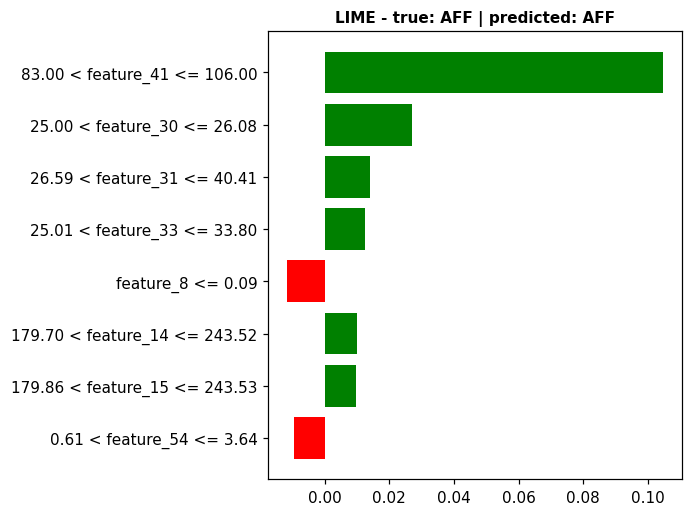

In [ ]:
# %% STEP 14: LIME (one local explanation) --------------------------------------
lime_exp = lime.lime_tabular.LimeTabularExplainer(
    training_data=SimpleImputer(strategy="median").fit(X_train).transform(X_train),
    feature_names=feature_cols, class_names=class_names,
    mode="classification", random_state=RANDOM_STATE)
exp = lime_exp.explain_instance(X_test[0], final_pipeline.predict_proba,
                                num_features=8, top_labels=1)
exp.as_pyplot_figure(label=int(y_pred[0]))
plt.title(f"LIME - true: {class_names[y_test[0]]} | predicted: {class_names[y_pred[0]]}",
          fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()


In [ ]:
# %% STEP 15: SAVE MODEL + SUMMARY ----------------------------------------------
joblib.dump(final_pipeline, "ecg_final_pipeline.joblib")
joblib.dump(label_encoder, "ecg_label_encoder.joblib")
joblib.dump(feature_cols, "ecg_feature_names.joblib")
print("Saved: ecg_final_pipeline.joblib, ecg_label_encoder.joblib, ecg_feature_names.joblib")

print(f"""
{'=' * 78}
RESULTS SUMMARY
{'=' * 78}
Dataset      : {len(df)} samples after de-duplication ({n_dups} duplicate rows removed),
               {N_FEATURES} features, {n_classes} classes {dict(zip(class_names, np.bincount(y).tolist()))}
Missing data : {int(df_raw[feature_cols].isnull().sum().sum())} values (median imputer still inside the pipeline)
Excluded     : RECORD_ID (row counter sorted by class)
Champion     : {champion_name}  (chosen by 5-fold CV Macro-F1 = {champ_cv_f1:.4f})
Test (N={len(y_test)}): Accuracy {test_acc:.4f} [{ci_acc[0]:.4f}, {ci_acc[1]:.4f}] | Macro-F1 {test_f1:.4f} [{ci_f1[0]:.4f}, {ci_f1[1]:.4f}]
               Macro-ROC-AUC {test_roc:.4f} [{ci_roc[0]:.4f}, {ci_roc[1]:.4f}]
Checks       : train-CV gap {train_f1 - champ_cv_f1:.4f} | CV-test gap {champ_cv_f1 - test_f1:+.4f} | shuffled-label acc {shuf_acc:.3f}
Limitation   : the CSV has no patient/recording ID, so rows from the same patient may land
               in both train and test. Real-world accuracy on NEW patients may be lower.
{'=' * 78}
""")


Saved: ecg_final_pipeline.joblib, ecg_label_encoder.joblib, ecg_feature_names.joblib

RESULTS SUMMARY
Dataset      : 1198 samples after de-duplication (2 duplicate rows removed),
               54 features, 4 classes {'AFF': 299, 'ARR': 300, 'CHF': 300, 'NSR': 299}
Missing data : 0 values (median imputer still inside the pipeline)
Excluded     : RECORD_ID (row counter sorted by class)
Champion     : Extra Trees  (chosen by 5-fold CV Macro-F1 = 0.9958)
Test (N=240): Accuracy 0.9875 [0.9708, 1.0000] | Macro-F1 0.9875 [0.9716, 1.0000]
               Macro-ROC-AUC 0.9993 [0.9979, 1.0000]
Checks       : train-CV gap 0.0042 | CV-test gap +0.0084 | shuffled-label acc 0.244
Limitation   : the CSV has no patient/recording ID, so rows from the same patient may land
               in both train and test. Real-world accuracy on NEW patients may be lower.



In [ ]:
# %% STEP 16: PREDICT ON A NEW SAMPLE -------------------------------------------
LABEL_MEANINGS = {"ARR": "Arrhythmia", "AFF": "Atrial Fibrillation",
                  "CHF": "Congestive Heart Failure", "NSR": "Normal Sinus Rhythm"}

def predict_ecg_condition(feature_vector,
                          pipeline_path="ecg_final_pipeline.joblib",
                          encoder_path="ecg_label_encoder.joblib"):
    """feature_vector: the 54 feature values (WITHOUT the id and label columns)."""
    vec = np.asarray(feature_vector, dtype=float).reshape(1, -1)
    if vec.shape[1] != N_FEATURES:
        raise ValueError(f"Expected {N_FEATURES} features, got {vec.shape[1]}")
    pipe, enc = joblib.load(pipeline_path), joblib.load(encoder_path)
    proba = pipe.predict_proba(vec)[0]
    code = enc.inverse_transform([int(np.argmax(proba))])[0]
    return {"predicted_code": code,
            "predicted_condition": LABEL_MEANINGS.get(code, code),
            "confidence": float(proba.max()),
            "class_probabilities": dict(zip(enc.classes_, proba.round(4).tolist()))}

demo = predict_ecg_condition(X_test[0])
print(f"Demo -> true: {class_names[y_test[0]]} | predicted: {demo['predicted_condition']} "
      f"({demo['confidence']:.1%})")
print(demo["class_probabilities"])

# Optional (Colab): download the saved model files to your computer
try:
    from google.colab import files
    for f in ["ecg_final_pipeline.joblib", "ecg_label_encoder.joblib", "ecg_feature_names.joblib"]:
        files.download(f)
except ImportError:
    pass

Demo -> true: AFF | predicted: Atrial Fibrillation (99.7%)
{'AFF': 0.9967, 'ARR': 0.0, 'CHF': 0.0033, 'NSR': 0.0}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>